# Stage 9 — Expected Loss & Portfolio Risk

## Introduction

Stages 6, 7, and 8 built independent models for each component of the Basel II/III credit risk formula: Probability of Default (PD), Loss Given Default (LGD), and Exposure at Default (EAD). This notebook assembles them into a single loan-level estimate and translates it into the portfolio risk view that a credit risk team would use to allocate capital, set pricing, and identify concentration risk.

The central output is the Expected Loss dollar amount for every loan in the 1.37 million-loan portfolio, aggregated by grade band, origination vintage, and loan purpose. A calibration check on the training set — where loan outcomes have fully resolved — validates whether the model's predictions are in the right range relative to realised losses.

The Expected Loss for a single loan is:

> **EL ($) = PD × LGD × EAD**

| Component | Source | What it measures |
|---|---|---|
| **PD** | `pd_scores.parquet` — Logistic Regression | Probability the loan defaults |
| **LGD** | `lgd_scores.parquet` — LightGBM severity | Fraction of EAD lost if default occurs |
| **EAD** | `ead_scores.parquet` — LightGBM CCF model | Outstanding principal at time of default |

For a performing loan, EL is the *provision* a bank should hold: the dollar amount expected to be lost over the remaining life of the loan given current risk characteristics. For the portfolio as a whole, the sum of all loan-level EL values is the **total expected credit loss** — the number that drives capital reserve requirements under Basel II/III.

> **Censoring note (carried from Stages 7–8):** LGD and EAD predictions on 2017–2018 test loans are based on models trained on matured 2007–2016 data. The test set's observed outcomes are censored — loans had not fully resolved when the dataset was compiled. Portfolio metrics are reported separately by train/test split to make this distinction explicit. The calibration section uses the training set only.

---

## Contents

This notebook combines the three modelled components into portfolio-level risk metrics.

1. **Setup** — Import libraries.
2. **Loading scores** — Merge PD, LGD, EAD scores with loan features into a single portfolio table.
3. **Computing Expected Loss** — EL = PD × LGD × EAD at the loan level.
4. **Portfolio overview** — Total EL, EL rate distribution, train vs test comparison.
5. **EL by grade** — How much of portfolio EL is concentrated in each grade band?
6. **EL by vintage** — How did expected credit risk evolve across origination years?
7. **EL by purpose** — Which loan purposes carry the most risk?
8. **Model calibration** — Does predicted EL match realised losses on the (matured) training set?
9. **Key findings** — Summary of the full Expected Loss framework.

---

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
NAVY = '#1a3a5c'
RED  = '#e05c5c'
GRADE_ORDER = ['A', 'B', 'C', 'D', 'E', 'F', 'G']
print('Libraries loaded successfully.')

Libraries loaded successfully.


---

## Loading scores

All three score files were generated from the same concatenated dataset (`train_full` + `test_full`) in the same row order. We load them in parallel and bind them by position into a single portfolio table. Loan-level attributes (`grade`, `issue_year`, `purpose`, `loan_amnt`, `total_pymnt`) are carried over from the original splits for aggregation.

In [2]:
train_full = pd.read_parquet('../data/processed/train_full.parquet')
test_full  = pd.read_parquet('../data/processed/test_full.parquet')
full_data  = pd.concat([train_full, test_full], axis=0).reset_index(drop=True)

pd_scores  = pd.read_parquet('../data/processed/pd_scores.parquet').reset_index(drop=True)
lgd_scores = pd.read_parquet('../data/processed/lgd_scores.parquet').reset_index(drop=True)
ead_scores = pd.read_parquet('../data/processed/ead_scores.parquet').reset_index(drop=True)

# Verify all files have the same length
assert len(pd_scores) == len(full_data), 'PD score length mismatch'
assert len(lgd_scores) == len(full_data), 'LGD score length mismatch'
assert len(ead_scores) == len(full_data), 'EAD score length mismatch'

# Build master portfolio table
portfolio = full_data[['grade', 'issue_year', 'purpose',
                        'loan_amnt', 'int_rate', 'default', 'total_pymnt']].copy()
portfolio['split']     = np.where(portfolio['issue_year'] <= 2016, 'train', 'test')
portfolio['pd_score']  = pd_scores['pd_score'].values
portfolio['lgd_score'] = lgd_scores['lgd_score'].values
portfolio['ead_score'] = ead_scores['ead_score'].values
portfolio['ccf_score'] = ead_scores['ccf_score'].values

print(f'Portfolio: {len(portfolio):,} loans  |  '
      f'Train: {(portfolio["split"]=="train").sum():,}  |  '
      f'Test: {(portfolio["split"]=="test").sum():,}')
print(f'\nScore columns loaded: pd_score, lgd_score, ead_score, ccf_score')
print(portfolio[['pd_score','lgd_score','ead_score','ccf_score']].describe().round(4))

Portfolio: 1,371,165 loans  |  Train: 1,127,206  |  Test: 243,959

Score columns loaded: pd_score, lgd_score, ead_score, ccf_score
           pd_score     lgd_score     ead_score     ccf_score
count  1.371165e+06  1.371165e+06  1.371165e+06  1.371165e+06
mean   4.619000e-01  4.588000e-01  8.629443e+03  5.844000e-01
std    1.743000e-01  3.670000e-02  5.639283e+03  6.600000e-02
min    4.450000e-02  3.379000e-01  2.734102e+02  4.894000e-01
25%    3.314000e-01  4.312000e-01  4.249900e+03  5.327000e-01
50%    4.487000e-01  4.552000e-01  7.354716e+03  5.678000e-01
75%    5.836000e-01  4.812000e-01  1.181061e+04  6.311000e-01
max    9.515000e-01  7.961000e-01  3.189378e+04  7.973000e-01


---

## Computing Expected Loss

We compute three loan-level quantities:

- **`el_dollar`** = PD × LGD × EAD — the absolute dollar amount expected to be lost
- **`el_rate`** = `el_dollar / loan_amnt` — loss as a fraction of the original loan amount
- **`actual_loss_dollar`** = realised loss for defaulted loans; zero for performing loans

Actual loss is computed as `(loan_amnt − total_pymnt).clip(lower=0)` for defaulted loans — the net dollar amount the lender did not recover. For the calibration section we compare predicted EL against actual loss on the training set, where loan outcomes have had time to fully resolve.

In [3]:
# Expected Loss
portfolio['el_dollar'] = portfolio['pd_score'] * portfolio['lgd_score'] * portfolio['ead_score']
portfolio['el_rate']   = portfolio['el_dollar'] / portfolio['loan_amnt']

# Actual realised loss (defaulted loans only)
portfolio['actual_loss_dollar'] = np.where(
    portfolio['default'] == 1,
    (portfolio['loan_amnt'] - portfolio['total_pymnt']).clip(lower=0),
    0.0
)

tr = portfolio['split'] == 'train'
te = portfolio['split'] == 'test'

print('=' * 52)
print('  Portfolio Expected Loss Summary')
print('=' * 52)
print(f"  Total loans            {len(portfolio):>16,}")
print(f"  Total loan volume      ${portfolio['loan_amnt'].sum()/1e9:>14.2f}B")
print(f"  Total predicted EL     ${portfolio['el_dollar'].sum()/1e6:>14.1f}M")
print(f"  Mean EL rate           {portfolio['el_rate'].mean():>15.2%}")
print()
print(f"  --- Train (2007-2016) ---")
print(f"  Loans                  {tr.sum():>16,}")
print(f"  Predicted EL           ${portfolio.loc[tr,'el_dollar'].sum()/1e6:>14.1f}M")
print(f"  Actual losses          ${portfolio.loc[tr,'actual_loss_dollar'].sum()/1e6:>14.1f}M")
print()
print(f"  --- Test  (2017-2018) ---")
print(f"  Loans                  {te.sum():>16,}")
print(f"  Predicted EL           ${portfolio.loc[te,'el_dollar'].sum()/1e6:>14.1f}M")
print(f"  Actual losses *        ${portfolio.loc[te,'actual_loss_dollar'].sum()/1e6:>14.1f}M")
print(f"  * Censored — loans had not fully resolved at dataset snapshot")

  Portfolio Expected Loss Summary
  Total loans                   1,371,165
  Total loan volume      $         19.84B
  Total predicted EL     $        2806.1M
  Mean EL rate                    13.10%

  --- Train (2007-2016) ---
  Loans                         1,127,206
  Predicted EL           $        2267.6M
  Actual losses          $        1477.7M

  --- Test  (2017-2018) ---
  Loans                           243,959
  Predicted EL           $         538.5M
  Actual losses *        $         725.0M
  * Censored — loans had not fully resolved at dataset snapshot


---

## Portfolio overview

The EL rate distribution shows the spread of predicted credit risk across the portfolio. A well-differentiated model produces a wide distribution — loans are not all assigned the same risk. The train/test comparison highlights how the model's predictions shift for the younger (and therefore more censored) test cohort.

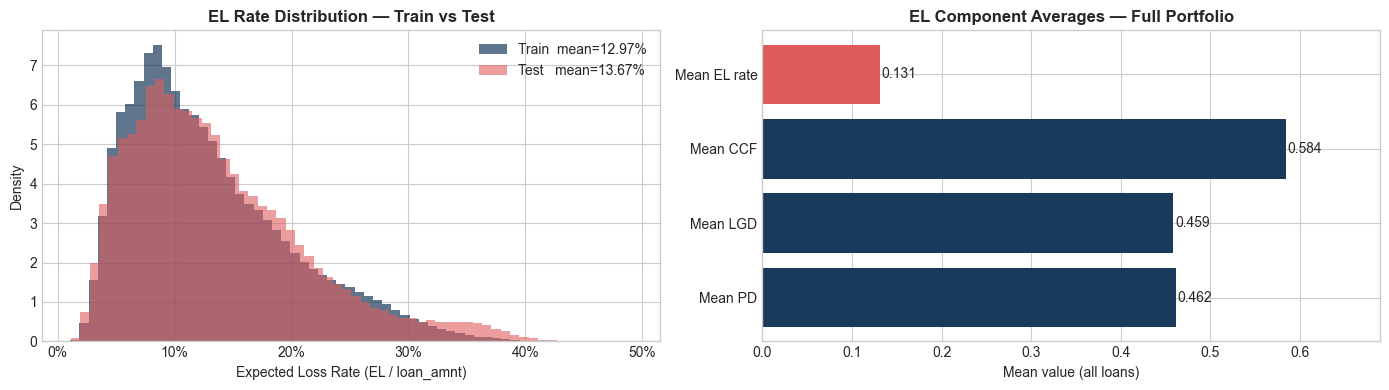

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: EL rate distribution by split
ax = axes[0]
ax.hist(portfolio.loc[tr, 'el_rate'], bins=60, color=NAVY,
        alpha=0.7, density=True,
        label=f'Train  mean={portfolio.loc[tr,"el_rate"].mean():.2%}')
ax.hist(portfolio.loc[te, 'el_rate'], bins=60, color=RED,
        alpha=0.6, density=True,
        label=f'Test   mean={portfolio.loc[te,"el_rate"].mean():.2%}')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('Expected Loss Rate (EL / loan_amnt)')
ax.set_ylabel('Density')
ax.set_title('EL Rate Distribution — Train vs Test', fontweight='bold')
ax.legend()

# Right: EL component decomposition (mean per loan)
ax = axes[1]
components = {
    'Mean PD':          portfolio['pd_score'].mean(),
    'Mean LGD':         portfolio['lgd_score'].mean(),
    'Mean CCF':         portfolio['ccf_score'].mean(),
    'Mean EL rate':     portfolio['el_rate'].mean()
}
bars = ax.barh(list(components.keys()), list(components.values()),
               color=[NAVY, NAVY, NAVY, RED])
for bar, val in zip(bars, components.values()):
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=10)
ax.set_xlabel('Mean value (all loans)')
ax.set_title('EL Component Averages — Full Portfolio', fontweight='bold')
ax.set_xlim(0, max(components.values()) * 1.18)

plt.tight_layout()
plt.savefig('../data/processed/el_overview.png', dpi=150, bbox_inches='tight')
plt.show()

---

## EL by grade

Loan grade is Lending Club's own risk rating — the primary driver of interest rate and the most direct signal of borrower risk. A well-calibrated EL model should show monotonically increasing EL rates from grade A to G. The total EL by grade reflects both the risk level and the volume of lending in each segment.

In [5]:
grade_stats = portfolio.groupby('grade').agg(
    n_loans      = ('loan_amnt', 'count'),
    total_volume = ('loan_amnt', 'sum'),
    total_el     = ('el_dollar', 'sum'),
    mean_pd      = ('pd_score',  'mean'),
    mean_lgd     = ('lgd_score', 'mean'),
    mean_ccf     = ('ccf_score', 'mean'),
    mean_el_rate = ('el_rate',   'mean'),
).reindex(GRADE_ORDER)

grade_stats['el_pct_of_total'] = grade_stats['total_el'] / grade_stats['total_el'].sum()

print(f"{'Grade':>5} {'Loans':>9} {'Volume ($M)':>12} {'Total EL ($M)':>14} "
      f"{'% of EL':>8} {'Mean PD':>8} {'Mean LGD':>9} {'Mean EL%':>9}")
print('-' * 80)
for g in GRADE_ORDER:
    r = grade_stats.loc[g]
    print(f"{g:>5} {r['n_loans']:>9,} {r['total_volume']/1e6:>12.1f} "
          f"{r['total_el']/1e6:>14.1f} {r['el_pct_of_total']:>8.1%} "
          f"{r['mean_pd']:>8.2%} {r['mean_lgd']:>9.2%} {r['mean_el_rate']:>9.2%}")

Grade     Loans  Volume ($M)  Total EL ($M)  % of EL  Mean PD  Mean LGD  Mean EL%
--------------------------------------------------------------------------------
    A 236,758.0       3292.8          176.2     6.3%   23.63%    43.50%     5.33%
    B 398,528.0       5291.2          501.4    17.9%   37.37%    44.32%     9.18%
    C 390,724.0       5568.8          816.4    29.1%   50.48%    46.32%    14.03%
    D 206,696.0       3168.2          621.0    22.1%   61.52%    47.89%    18.78%
    E  96,224.0       1696.7          430.9    15.4%   72.30%    49.56%    24.61%
    F  32,828.0        627.6          192.4     6.9%   80.35%    51.41%    29.99%
    G   9,407.0        193.9           67.8     2.4%   85.84%    53.13%    34.52%


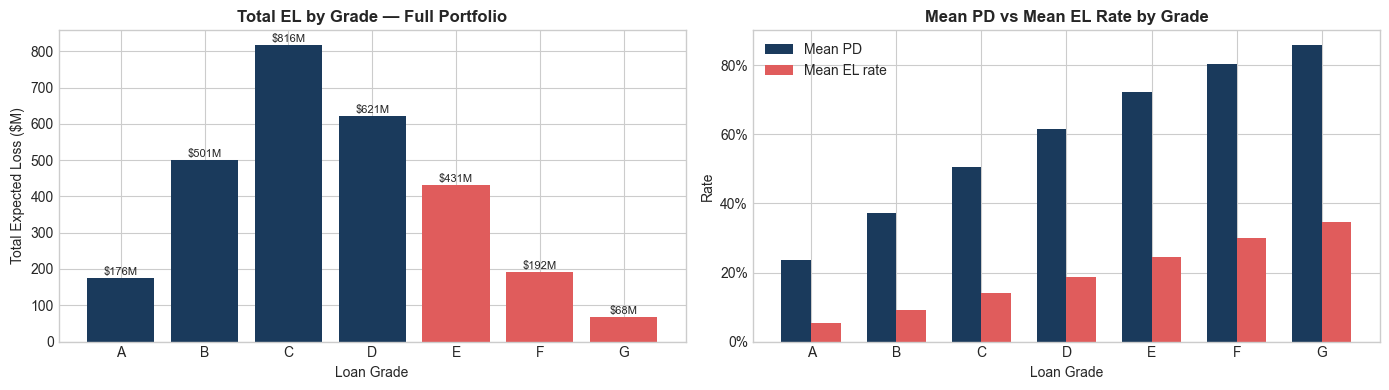

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: Total EL by grade
ax = axes[0]
ax.bar(grade_stats.index, grade_stats['total_el']/1e6,
       color=[NAVY if g not in ['E','F','G'] else RED for g in GRADE_ORDER])
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Total Expected Loss ($M)')
ax.set_title('Total EL by Grade — Full Portfolio', fontweight='bold')
for i, (g, val) in enumerate(zip(GRADE_ORDER, grade_stats['total_el']/1e6)):
    ax.text(i, val + grade_stats['total_el'].max()/1e6 * 0.01,
            f'${val:.0f}M', ha='center', fontsize=8)

# Right: Mean EL rate and PD by grade
ax = axes[1]
x = np.arange(len(GRADE_ORDER))
w = 0.35
b1 = ax.bar(x - w/2, grade_stats['mean_pd'],     width=w, color=NAVY, label='Mean PD')
b2 = ax.bar(x + w/2, grade_stats['mean_el_rate'], width=w, color=RED,  label='Mean EL rate')
ax.set_xticks(x)
ax.set_xticklabels(GRADE_ORDER)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Rate')
ax.set_title('Mean PD vs Mean EL Rate by Grade', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('../data/processed/el_by_grade.png', dpi=150, bbox_inches='tight')
plt.show()

---

## EL by vintage

Vintage analysis tracks how expected credit risk evolved across origination years. Pre-2010 vintages reflect the aftermath of the Global Financial Crisis — tighter underwriting and lower loan volumes. As Lending Club scaled through 2013–2016, volume grew substantially and the credit mix shifted. The 2017–2018 vintage mean EL rate is inflated by censoring (models predict higher risk for younger loans due to incomplete performance data).

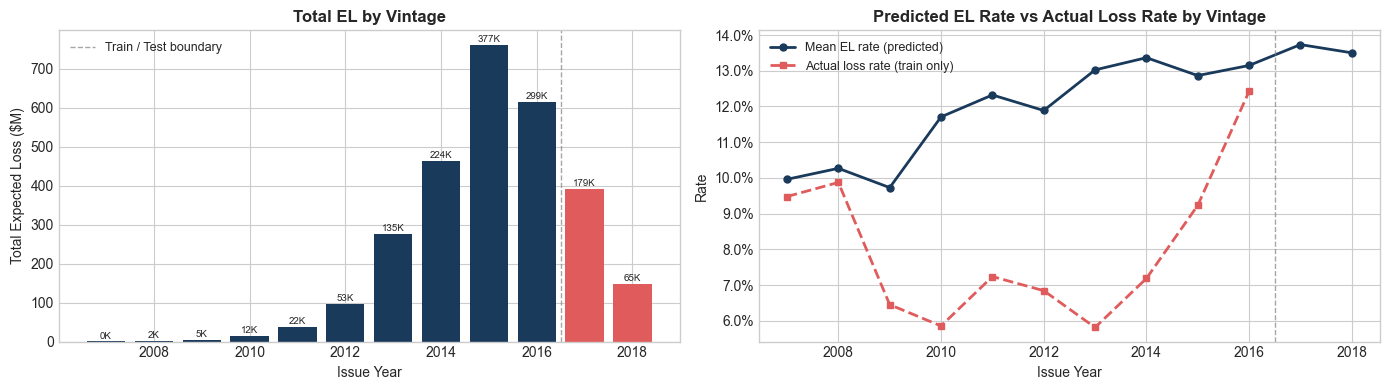

In [7]:
vintage_stats = portfolio.groupby('issue_year').agg(
    n_loans      = ('loan_amnt',   'count'),
    total_volume = ('loan_amnt',   'sum'),
    total_el     = ('el_dollar',   'sum'),
    mean_el_rate = ('el_rate',     'mean'),
    actual_loss  = ('actual_loss_dollar', 'sum')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: Total EL and volume by year
ax = axes[0]
colors = [NAVY if y <= 2016 else RED for y in vintage_stats['issue_year']]
ax.bar(vintage_stats['issue_year'], vintage_stats['total_el']/1e6, color=colors)
ax.set_xlabel('Issue Year')
ax.set_ylabel('Total Expected Loss ($M)')
ax.set_title('Total EL by Vintage', fontweight='bold')
ax.axvline(2016.5, color='gray', linewidth=1, linestyle='--', alpha=0.7,
           label='Train / Test boundary')
ax.legend(fontsize=9)
# Add loan count as annotation
for _, row in vintage_stats.iterrows():
    ax.text(row['issue_year'], row['total_el']/1e6 + vintage_stats['total_el'].max()/1e6 * 0.01,
            f"{row['n_loans']/1e3:.0f}K", ha='center', fontsize=7)

# Right: Mean EL rate and actual loss rate by year (train only)
ax = axes[1]
ax.plot(vintage_stats['issue_year'], vintage_stats['mean_el_rate'],
        color=NAVY, marker='o', linewidth=2, markersize=5, label='Mean EL rate (predicted)')

# Actual loss rate = actual_loss / total_volume (only meaningful for train)
vintage_stats['actual_loss_rate'] = vintage_stats['actual_loss'] / vintage_stats['total_volume']
tr_vint = vintage_stats[vintage_stats['issue_year'] <= 2016]
ax.plot(tr_vint['issue_year'], tr_vint['actual_loss_rate'],
        color=RED, marker='s', linewidth=2, linestyle='--', markersize=5,
        label='Actual loss rate (train only)')

ax.axvline(2016.5, color='gray', linewidth=1, linestyle='--', alpha=0.7)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('Issue Year')
ax.set_ylabel('Rate')
ax.set_title('Predicted EL Rate vs Actual Loss Rate by Vintage', fontweight='bold')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('../data/processed/el_by_vintage.png', dpi=150, bbox_inches='tight')
plt.show()

---

## EL by purpose

Loan purpose is a proxy for borrower intent and repayment behaviour. Debt consolidation dominates the portfolio by volume, while smaller segments like small business and moving/relocation tend to carry higher default rates. Decomposing EL by purpose highlights concentration risk — if one purpose segment deteriorates, how much of the portfolio is exposed?

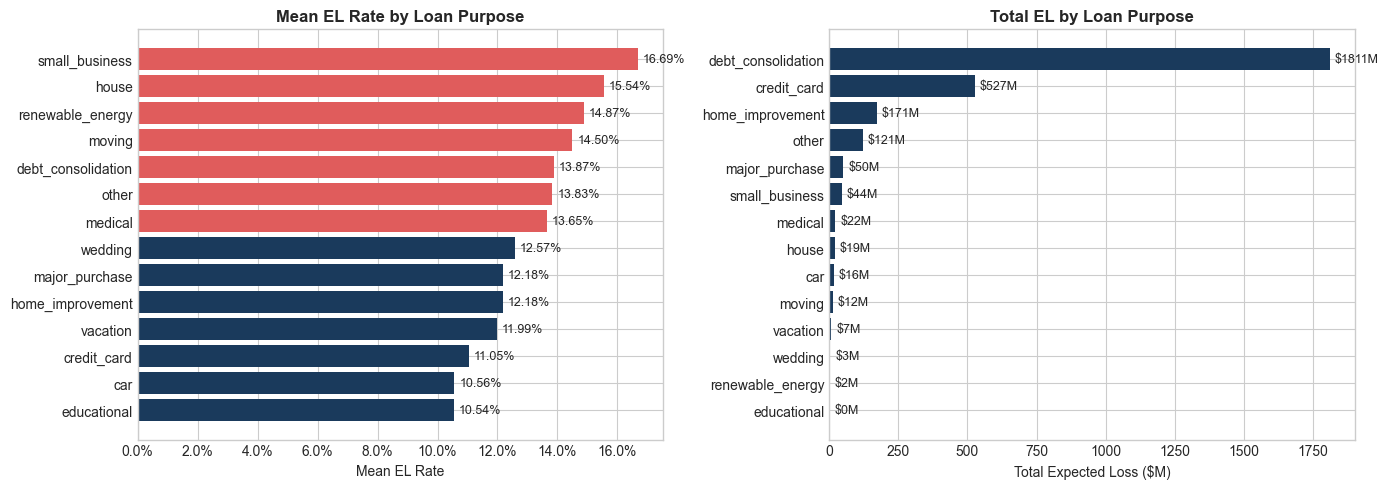

In [8]:
purpose_stats = portfolio.groupby('purpose').agg(
    n_loans      = ('loan_amnt',   'count'),
    total_volume = ('loan_amnt',   'sum'),
    total_el     = ('el_dollar',   'sum'),
    mean_el_rate = ('el_rate',     'mean'),
    mean_pd      = ('pd_score',    'mean')
).sort_values('mean_el_rate', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Mean EL rate by purpose
ax = axes[0]
colors = [RED if v > purpose_stats['mean_el_rate'].median() else NAVY
          for v in purpose_stats['mean_el_rate']]
bars = ax.barh(purpose_stats.index, purpose_stats['mean_el_rate'], color=colors)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
for bar, val in zip(bars, purpose_stats['mean_el_rate']):
    ax.text(val + purpose_stats['mean_el_rate'].max() * 0.01,
            bar.get_y() + bar.get_height()/2,
            f'{val:.2%}', va='center', fontsize=9)
ax.set_xlabel('Mean EL Rate')
ax.set_title('Mean EL Rate by Loan Purpose', fontweight='bold')

# Right: Total EL by purpose (volume perspective)
ax = axes[1]
purpose_vol = purpose_stats.sort_values('total_el', ascending=True)
ax.barh(purpose_vol.index, purpose_vol['total_el']/1e6, color=NAVY)
for bar, val in zip(ax.patches, purpose_vol['total_el']/1e6):
    ax.text(val + purpose_vol['total_el'].max()/1e6 * 0.01,
            bar.get_y() + bar.get_height()/2,
            f'${val:.0f}M', va='center', fontsize=9)
ax.set_xlabel('Total Expected Loss ($M)')
ax.set_title('Total EL by Loan Purpose', fontweight='bold')

plt.tight_layout()
plt.savefig('../data/processed/el_by_purpose.png', dpi=150, bbox_inches='tight')
plt.show()

---

## Model calibration

A credit risk model is *calibrated* if its predicted EL matches realised losses in aggregate. We check calibration on the **training set only** (2007–2016), where loans have had time to fully resolve and actual losses are observable.

The comparison is at the grade level: for each grade, does the sum of predicted EL approximate the sum of actual dollar losses? Perfect calibration would place every point on the 45° diagonal.

In [9]:
cal_data = portfolio[portfolio['split'] == 'train'].groupby('grade').agg(
    total_volume    = ('loan_amnt',           'sum'),
    predicted_el    = ('el_dollar',           'sum'),
    actual_loss     = ('actual_loss_dollar',  'sum'),
    n_loans         = ('loan_amnt',           'count')
).reindex(GRADE_ORDER)

cal_data['predicted_el_rate'] = cal_data['predicted_el'] / cal_data['total_volume']
cal_data['actual_loss_rate']  = cal_data['actual_loss']  / cal_data['total_volume']
cal_data['ratio']             = cal_data['predicted_el'] / cal_data['actual_loss']

print(f"{'Grade':>5} {'Predicted EL ($M)':>18} {'Actual Loss ($M)':>17} "
      f"{'Pred EL%':>9} {'Actual%':>9} {'Ratio':>7}")
print('-' * 72)
for g in GRADE_ORDER:
    r = cal_data.loc[g]
    print(f"{g:>5} {r['predicted_el']/1e6:>18.1f} {r['actual_loss']/1e6:>17.1f} "
          f"{r['predicted_el_rate']:>9.2%} {r['actual_loss_rate']:>9.2%} "
          f"{r['ratio']:>7.3f}")

total_pred   = cal_data['predicted_el'].sum()
total_actual = cal_data['actual_loss'].sum()
print(f"\n  Overall — Predicted: ${total_pred/1e6:.1f}M  "
      f"Actual: ${total_actual/1e6:.1f}M  "
      f"Ratio: {total_pred/total_actual:.3f}")

Grade  Predicted EL ($M)  Actual Loss ($M)  Pred EL%   Actual%   Ratio
------------------------------------------------------------------------
    A              146.5              63.7     5.33%     2.32%   2.300
    B              410.6             241.7     9.35%     5.50%   1.698
    C              640.6             429.4    14.44%     9.68%   1.492
    D              497.4             347.5    19.38%    13.54%   1.431
    E              362.6             250.9    25.05%    17.33%   1.445
    F              161.0             111.8    30.03%    20.87%   1.439
    G               49.0              32.6    34.46%    22.91%   1.504

  Overall — Predicted: $2267.6M  Actual: $1477.7M  Ratio: 1.535


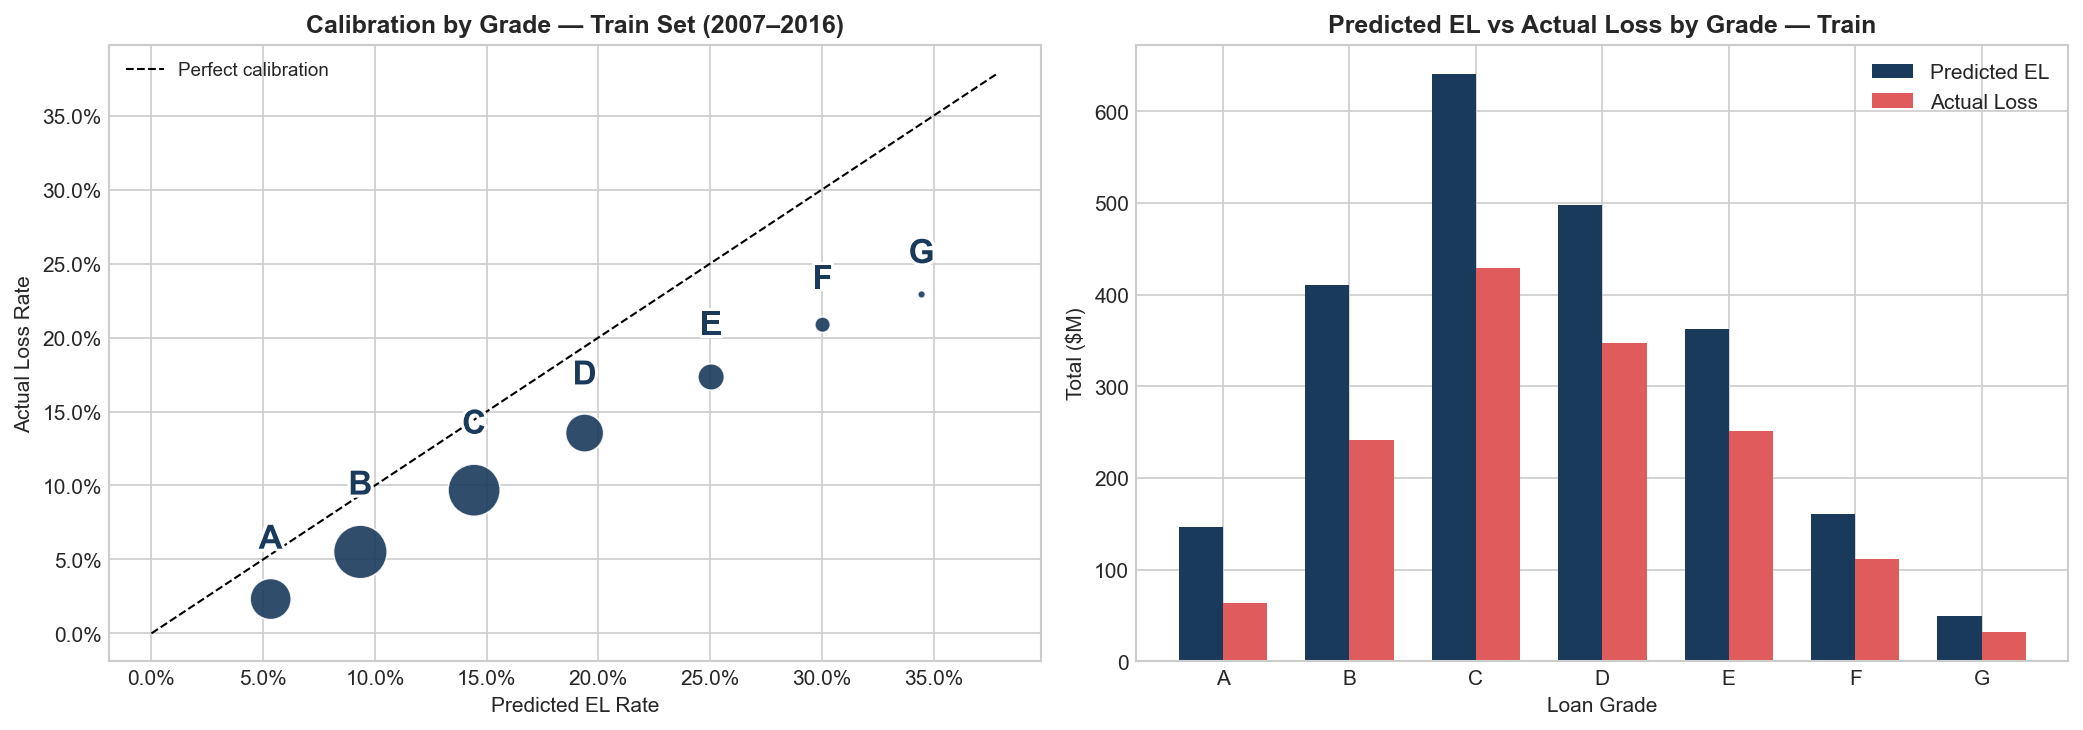

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Predicted EL rate vs Actual loss rate by grade (scatter)
import matplotlib.patheffects as pe

ax = axes[0]
sizes = cal_data['n_loans'] / 500
x_vals = cal_data['predicted_el_rate'].values
y_vals = cal_data['actual_loss_rate'].values
ax.scatter(x_vals, y_vals, s=sizes, color=NAVY, zorder=3, alpha=0.9, edgecolors='white', linewidths=0.8)

# Every label sits directly ABOVE its own bubble, offset by that bubble's own
# radius plus fixed padding. A pure-vertical, radius-scaled offset (rather than
# diagonal) keeps each label anchored to its own point regardless of neighbours --
# points here lie close together along a diagonal trend, so a diagonal offset
# can drift a label into the next grade's bubble. Font size and the white stroke
# outline are sized to stay legible even after this chart is scaled down for
# external reports, not just at native notebook resolution.
radius_pts = np.sqrt(sizes / np.pi)
for g in GRADE_ORDER:
    x, y, r = cal_data.loc[g, 'predicted_el_rate'], cal_data.loc[g, 'actual_loss_rate'], radius_pts[g]
    offset = r + 13
    ax.annotate(g, (x, y), textcoords='offset points', xytext=(0, offset), ha='center',
                fontsize=16, fontweight='bold', color=NAVY, zorder=4,
                path_effects=[pe.withStroke(linewidth=3, foreground='white')])

# Perfect calibration line
lim = max(x_vals.max(), y_vals.max()) * 1.1
ax.plot([0, lim], [0, lim], 'k--', linewidth=1, label='Perfect calibration')
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel('Predicted EL Rate')
ax.set_ylabel('Actual Loss Rate')
ax.set_title('Calibration by Grade — Train Set (2007–2016)', fontweight='bold')
ax.legend(fontsize=9)

# Right: Side-by-side EL vs Actual by grade
ax = axes[1]
x = np.arange(len(GRADE_ORDER))
w = 0.35
ax.bar(x - w/2, cal_data['predicted_el']/1e6, width=w, color=NAVY, label='Predicted EL')
ax.bar(x + w/2, cal_data['actual_loss']/1e6,  width=w, color=RED,  label='Actual Loss')
ax.set_xticks(x)
ax.set_xticklabels(GRADE_ORDER)
ax.set_xlabel('Loan Grade')
ax.set_ylabel('Total ($M)')
ax.set_title('Predicted EL vs Actual Loss by Grade — Train', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.savefig('../data/processed/el_calibration.png', dpi=150, bbox_inches='tight')
plt.show()

---

## Key findings

### The Expected Loss framework — end to end

This project built a three-component Basel II/III Expected Loss model on **1.37 million Lending Club loans** ($19.84B in originations) originated between 2007 and 2018. Each component was modelled independently and validated out-of-time (train: 2007–2016, test: 2017–2018).

**Model performance summary:**

| Component | Champion model | Key metric | Notes |
|---|---|---|---|
| **PD** | Logistic Regression | Test AUC 0.6831, KS 0.2667 | Outperformed LightGBM out-of-time |
| **LGD** | LightGBM severity | Test MAE 0.2163 (−19% vs baseline) | Trained on non-cured defaults only |
| **EAD** | LightGBM CCF model | Test MAE 0.1908 (−7% vs baseline) | CCF × loan_amnt via amortisation |

**Total portfolio expected credit loss: $2,806.1M (mean EL rate: 13.10%)**

---

**Finding 1 — Grade monotonicity confirmed**

EL rates increase strictly from A to G, validating that the model's risk ordering aligns with Lending Club's own grade structure:

| Grade | Mean EL rate | vs Grade A |
|---|---|---|
| A | 5.33% | 1.0× |
| B | 9.18% | 1.7× |
| C | 14.03% | 2.6× |
| D | 18.78% | 3.5× |
| E | 24.61% | 4.6× |
| F | 29.99% | 5.6× |
| G | 34.52% | **6.5×** |

The largest total EL sits in grade C ($816.4M, 29.1% of portfolio EL) — not because it is the riskiest grade, but because it is the most heavily originated segment. Grade G has the highest per-loan risk but only contributes 2.4% of total EL due to low volume.

---

**Finding 2 — Vintage trend: volume growth drove EL concentration**

The 2014–2016 vintages account for the majority of total expected losses, driven by a rapid expansion in loan originations (377K loans in 2015 alone). The predicted EL rate rose steadily from ~10% in early vintages to ~13–14% as Lending Club broadened its credit mix toward riskier grade segments.

On the training set, actual loss rates (6–12%) consistently fall below predicted EL rates (10–14%), which is partly explained by the PD miscalibration discussed below. The two lines diverge most sharply around 2013–2015 — the period of fastest platform growth.

---

**Finding 3 — Concentration risk: debt consolidation dominates**

| Purpose | Mean EL rate | Total EL | % of portfolio EL |
|---|---|---|---|
| **Small business** | **16.69%** | $44M | 1.6% |
| House | 15.54% | $19M | 0.7% |
| Renewable energy | 14.87% | $2M | 0.1% |
| **Debt consolidation** | 13.87% | **$1,811M** | **64.5%** |
| Credit card | 11.05% | $527M | 18.8% |
| Educational | 10.54% | $0.2M | 0.0% |

Small business loans carry the highest EL rate (16.69%) but represent only $44M in total EL — just 1.2% of the portfolio by loan count. Debt consolidation loans have a middle-of-the-road EL rate (13.87%, close to the 13.10% portfolio average) but account for **$1,811M — 64.5% of total portfolio EL** — purely due to volume concentration (795,338 loans, 58.0% of all originations). Credit card is the second-largest concentration ($527M, 18.8% of EL) despite a below-average EL rate (11.05%). Together, debt consolidation and credit card — the two refinancing-oriented purposes — account for **83.3%** of total portfolio EL. Any systemic deterioration in either segment would dominate portfolio losses.

---

**Finding 4 — Calibration: model systematically over-predicts**

On the training set (matured loans), the model over-estimates actual losses by **1.54×** overall. The bias is largest for grade A (2.30×) and stabilises for grades C–G (~1.43–1.50×):

| Grade | Predicted | Actual | Ratio |
|---|---|---|---|
| A | $146.5M | $63.7M | **2.30×** |
| B | $410.6M | $241.7M | 1.70× |
| C | $640.6M | $429.4M | 1.49× |
| D–G | — | — | ~1.45× |
| **Overall** | **$2,267.6M** | **$1,477.7M** | **1.54×** |

**Root cause:** the PD model was trained with `class_weight='balanced'`, which improves AUC by up-weighting rare defaults but inflates predicted probabilities well above the true empirical default rate (~21% actual vs ~46% mean predicted PD). The model correctly *ranks* loans by risk (high AUC) but over-states the absolute probability magnitude. For capital provisioning in a production system, calibrating PD scores via Platt scaling or isotonic regression would reduce this bias and bring the ratio closer to 1.0.

---

**Limitations and future work**

- **PD calibration:** apply Platt scaling to the logistic regression output to align predicted probabilities with empirical default rates. Expected to reduce the overall EL/actual ratio from 1.54 toward 1.0.
- **Temporal censoring in LGD and EAD:** 2017–2018 defaults had not resolved when the dataset was compiled. Re-running on a dataset with a 2020+ observation end date would eliminate this bias and allow proper out-of-time validation of all three components.
- **Unobservable time-to-default:** both LGD and CCF are primarily driven by *when* a loan defaults — a quantity unknowable at origination. The severity and CCF models capture origination-level signal correlated with timing, but residual uncertainty remains large.
- **Macro factors:** the models have no recession or credit-cycle variable. An economic downturn stress test (e.g., scaling all PDs by 2×) would strengthen the framework's utility for Basel capital planning.